# Selección de lambda PDE con validación y prueba externa

Este experimento fija PCA en `k=8`, selecciona el peso de la pérdida física con validación y evalúa después un conjunto externo fijo. La prueba solo se calcula para el peso seleccionado y para la PINN base.


## Regla y particiones

- Se entrenan `lambda_PDE = 1, 2, 5, 10` con 10 semillas y 5000 pasos. Por semilla, las variantes PCA comparten inicialización y muestras.
- La regla elige el menor residuo PDE medio de validación entre los pesos cuya RMSE media no exceda en más de 15% la mejor RMSE PCA.
- Un conjunto externo fijo de 20 tiempos se excluye de todas las particiones de entrenamiento y validación. Después de fijar `lambda_PDE`, se evalúa ese conjunto para la variante seleccionada y la PINN base.
- Los residuos de entrenamiento usan autodiferenciación de JAX. Los residuos de validación/prueba se calculan con el mismo operador discreto sobre la malla para todos los métodos.
- El conjunto externo no participó en la selección de `lambda_PDE` de esta corrida. Experimentos exploratorios anteriores usaron el mismo archivo con particiones aleatorias; para una evaluación final del proyecto conviene confirmar el peso seleccionado con una nueva trayectoria de referencia.


In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import SVG, display

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
RUN_DIR = ROOT / "results" / "burgers" / "base_vs_pca" / "validation_selected_lambda_nested_10_seeds_v1"
CONFIG = json.loads((RUN_DIR / "config.json").read_text(encoding="utf-8"))
RESULT = json.loads((RUN_DIR / "summary.json").read_text(encoding="utf-8"))
SELECTION = json.loads((RUN_DIR / "selection.json").read_text(encoding="utf-8"))
VALIDATION = pd.read_csv(RUN_DIR / "validation_checkpoint_metrics.csv")
TEST = pd.read_csv(RUN_DIR / "selected_test_metrics.csv")
print(f"JAX {RESULT['runtime']['jax']} | {RESULT['runtime']['device']}")
print(f"Semillas: {len(CONFIG['seeds'])}; holdout externo: {len(RESULT['outer_test_indices'])} tiempos")
print(f"lambda PDE seleccionado: {SELECTION['selected_lambda_pde']}")


JAX 0.12.0.1 | cpu:0
Semillas: 10; holdout externo: 20 tiempos
lambda PDE seleccionado: 2.0


## Selección basada solo en validación


In [2]:
rule = RESULT["selection"]
rows = []
for candidate in rule["candidates"]:
    rows.append({
        "lambda PDE": candidate["lambda_pde"],
        "RMSE validación": f"{candidate['validation_rmse']['mean']:.4f} ± {candidate['validation_rmse']['std']:.4f}",
        "Residuo PDE validación": f"{candidate['validation_pde_residual_rms']['mean']:.4f} ± {candidate['validation_pde_residual_rms']['std']:.4f}",
        "Dentro de la tolerancia": candidate["lambda_pde"] in rule["feasible_lambdas"],
        "Elegido": candidate["lambda_pde"] == rule["selected_lambda_pde"],
    })
print(f"Mejor RMSE PCA={rule['best_validation_rmse']:.4f}; límite={rule['validation_rmse_cutoff']:.4f}")
display(pd.DataFrame(rows))


Mejor RMSE PCA=0.2095; límite=0.2410


lambda PDE,RMSE validación,Residuo PDE validación,Dentro de la tolerancia,Elegido
1.0,0.2095 ± 0.0128,0.2440 ± 0.0305,Sí,
2.0,0.2387 ± 0.0143,0.1872 ± 0.0261,Sí,SELECCIONADO
5.0,0.2779 ± 0.0176,0.1378 ± 0.0266,No,
10.0,0.3036 ± 0.0214,0.1061 ± 0.0175,No,


## Prueba externa: solo base y lambda seleccionado


In [3]:
rows = []
for model, stats in RESULT["selected_test_summary"].items():
    rows.append({"Modelo": model,
        "RMSE": f"{stats['test_rmse']['mean']:.4f} ± {stats['test_rmse']['std']:.4f}",
        "Error relativo L2": f"{stats['test_relative_l2']['mean']:.4f} ± {stats['test_relative_l2']['std']:.4f}",
        "Residuo RMS Burgers": f"{stats['test_pde_residual_rms']['mean']:.4f} ± {stats['test_pde_residual_rms']['std']:.4f}",
        "Tiempo pipeline": f"{stats['pipeline_seconds']['mean']:.2f} ± {stats['pipeline_seconds']['std']:.2f} s"})
display(pd.DataFrame(rows))


Modelo,RMSE,Error relativo L2,Residuo RMS Burgers,Tiempo pipeline
PINN base,0.1087 ± 0.0136,0.1840 ± 0.0231,0.8235 ± 0.1352,11.44 ± 0.43 s
"PCA k=8, lambda_PDE=2",0.2231 ± 0.0057,0.3775 ± 0.0097,0.1979 ± 0.0173,7.20 ± 0.25 s


## Diferencias pareadas en la prueba externa


In [4]:
rows = []
for metric, label in [("test_relative_l2", "Error relativo L2"),
                      ("test_pde_residual_rms", "Residuo RMS PDE"),
                      ("pipeline_seconds", "Tiempo pipeline")]:
    value = RESULT["paired_selected_test_differences"][metric]
    rows.append({"Métrica": label,
                 "Diferencia seleccionada PCA − base": value["selected_PCA_minus_base_mean"],
                 "Semillas con diferencia menor": f"{value['selected_PCA_better_count']}/{value['n']}"})
display(pd.DataFrame(rows))


Métrica,Diferencia seleccionada PCA − base,Semillas con diferencia menor
Error relativo L2,0.1935,0/10
Residuo RMS PDE,-0.6257,10/10
Tiempo pipeline,-4.2471,10/10


## Tendencias de validación


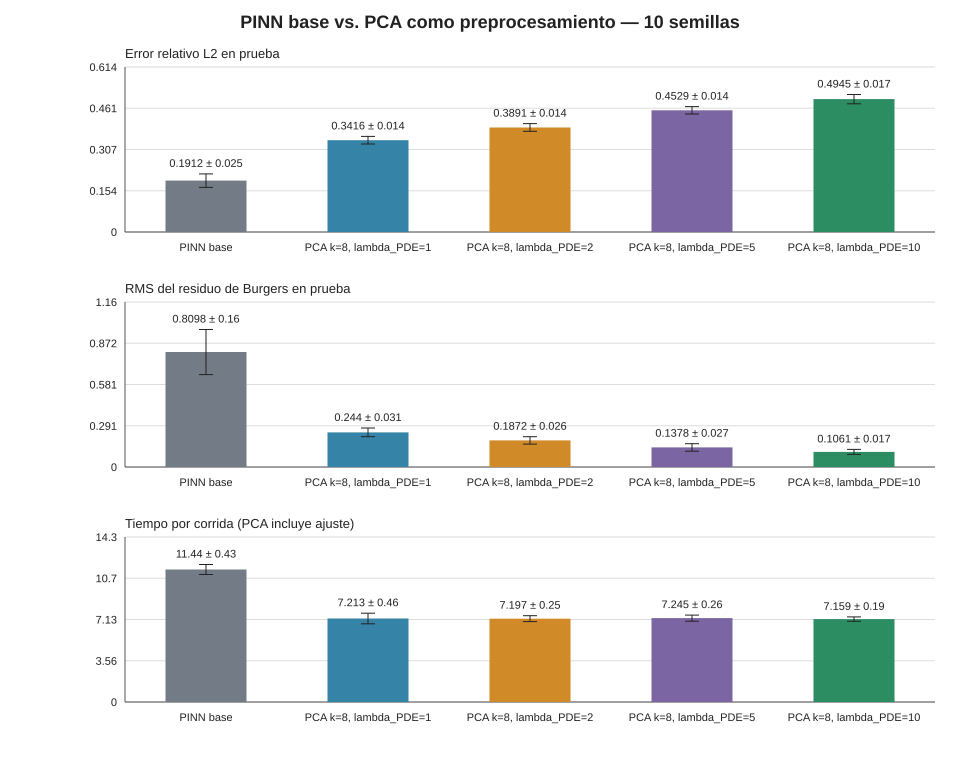

In [5]:
display(SVG(filename=str(RUN_DIR / "validation_candidates.svg")))


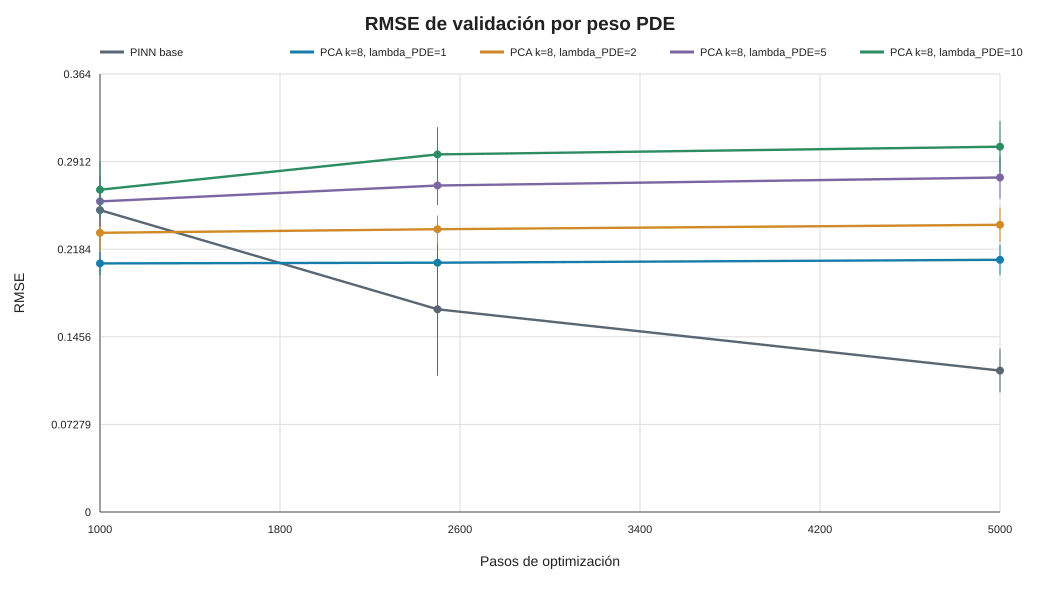

In [6]:
display(SVG(filename=str(RUN_DIR / "validation_rmse_vs_steps.svg")))


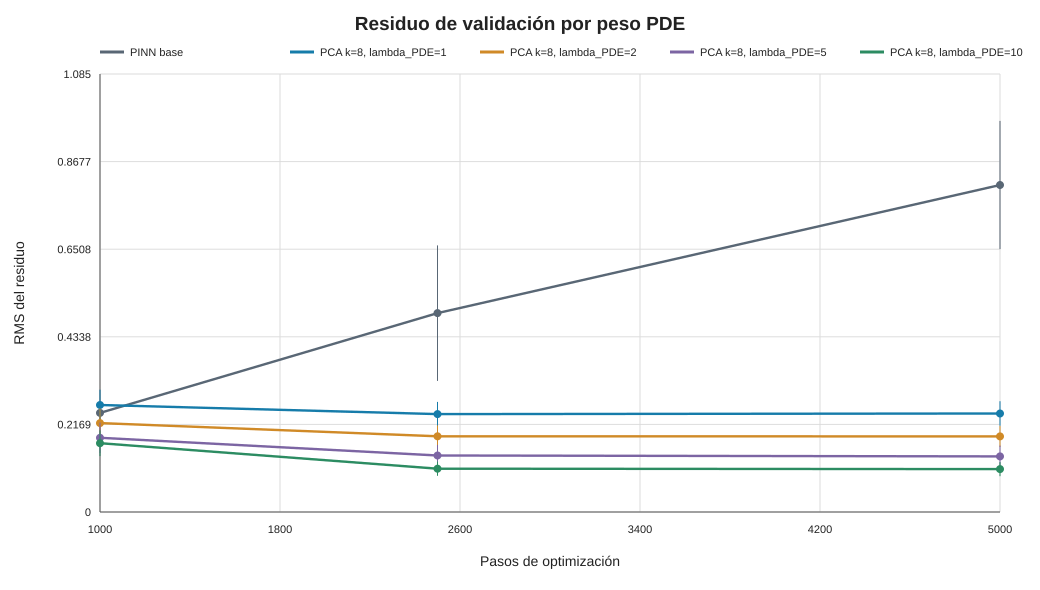

In [7]:
display(SVG(filename=str(RUN_DIR / "validation_residual_vs_steps.svg")))


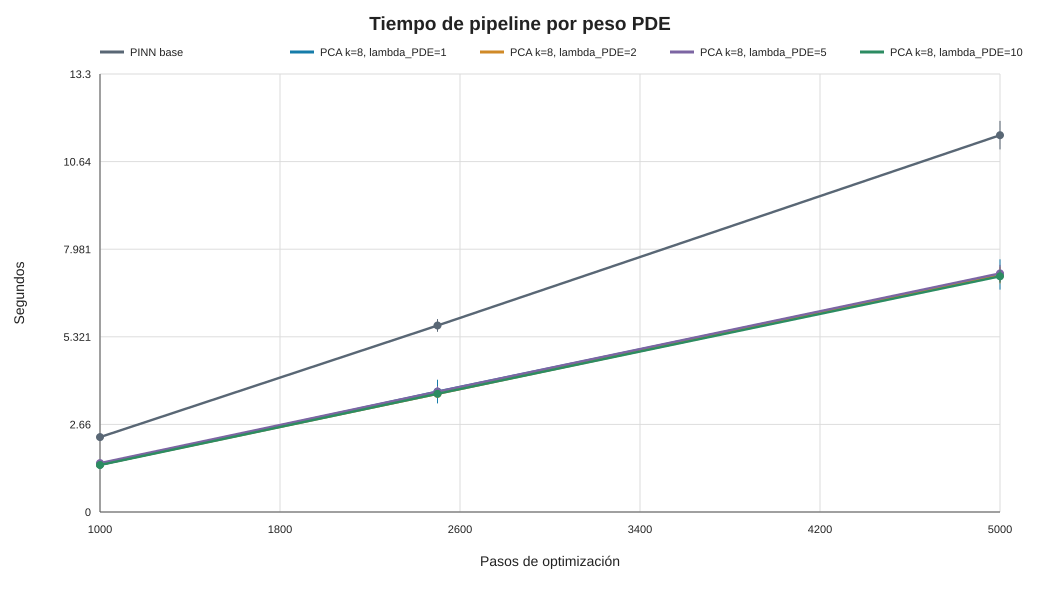

In [8]:
display(SVG(filename=str(RUN_DIR / "pipeline_time_vs_steps.svg")))


## Comparación final en la prueba externa


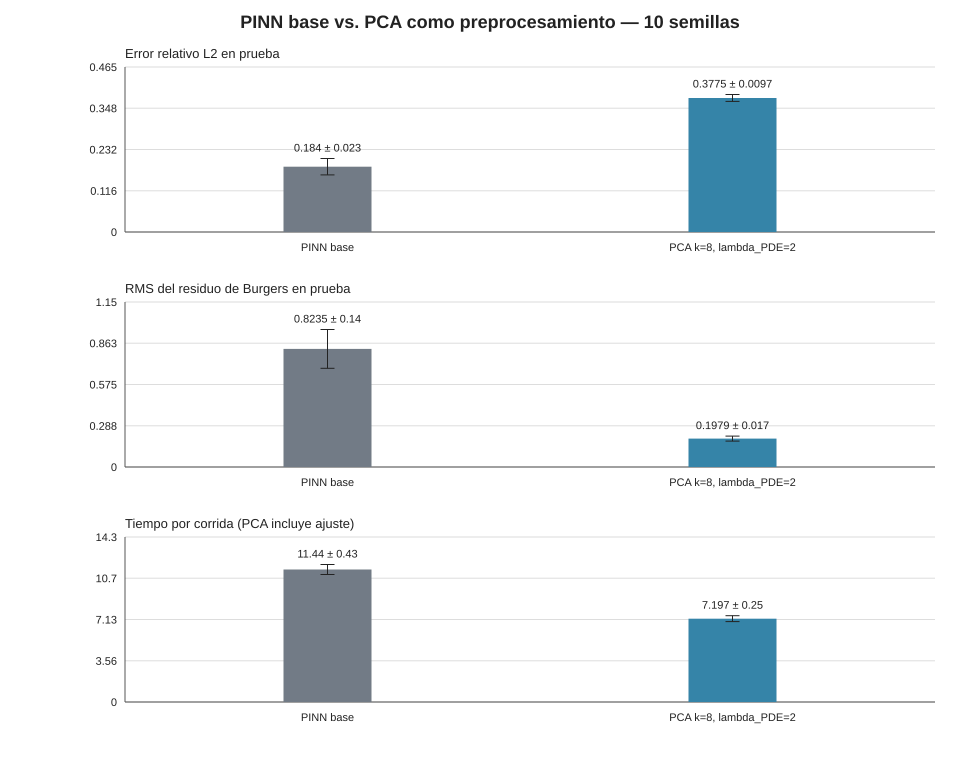

In [9]:
display(SVG(filename=str(RUN_DIR / "selected_test_comparison.svg")))


## Interpretación

La regla seleccionó `lambda_PDE=2`: pasa el límite de RMSE de validación del 15% y, entre los pesos admisibles, tiene el menor residuo PDE. En la prueba externa, el residuo de la variante seleccionada es menor que el de la base, pero su error de solución es mayor; conserva una reducción de tiempo en esta ejecución.

La prueba está separada de la selección dentro de este protocolo. Como en experimentos anteriores se usó el mismo archivo de datos con particiones aleatorias, para una afirmación final del proyecto conviene confirmar el peso elegido sobre una trayectoria de Burgers nueva que no haya intervenido en los análisis previos.


## Reproducir

La regla y partición están en `configs/burgers_validation_selected_lambda.json`; el ejecutor es `scripts/run_validation_selected_sweep.py`. El notebook presenta los artefactos guardados. Para regenerar la selección y la evaluación externa, ejecuta el script desde la raíz del repositorio.
